In [36]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

import warnings 
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

df = pd.read_csv("AIML Dataset.csv")
print(df.info()) # tells about each column and their data type nd totlal no. of rows 

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB
None


In [37]:
print(df.columns) # gives a full list of the column names

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')


In [38]:
print(df["isFraud"].value_counts()) # counts the no. of entries that have been declared as fraud in the dataset, these are the ones that have been predefined as fraud and its not the ones which have been detected 

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [39]:
print(df["isFlaggedFraud"].value_counts()) # counts the no. of entries that have been flagged as fraud in the dataset

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64


In [40]:
print(df.shape)

(6362620, 11)


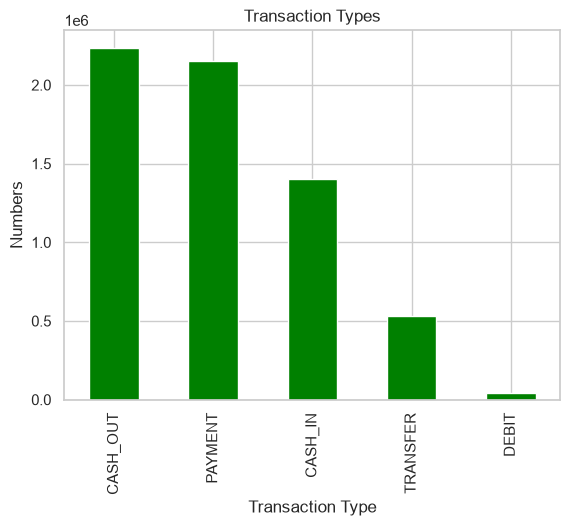

'This showed the bar graph of types of fraud in the dataset'

In [41]:
df["type"].value_counts().plot(kind="bar", title="Transaction Types", color = "green")
plt.xlabel("Transaction Type")
plt.ylabel("Numbers") 
plt.show()

'''This showed the bar graph of types of fraud in the dataset'''

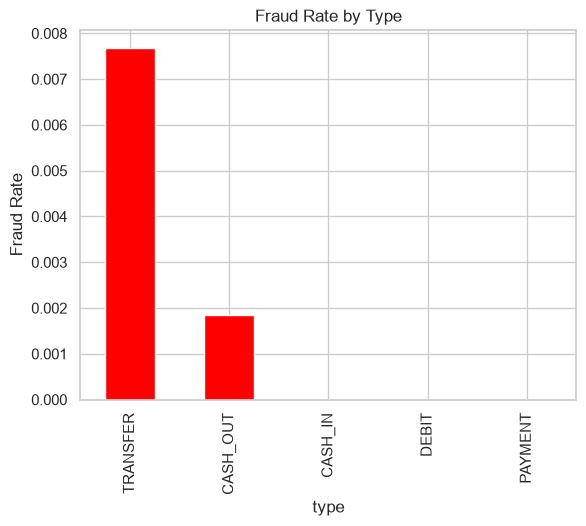

'This showed the bar graph of how many frauds per type'

In [42]:
fraud_category = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_category.plot(kind="bar", title="Fraud Rate by Type", color="red")
plt.ylabel("Fraud Rate")
plt.show()

'''This showed the bar graph of how many frauds per type'''

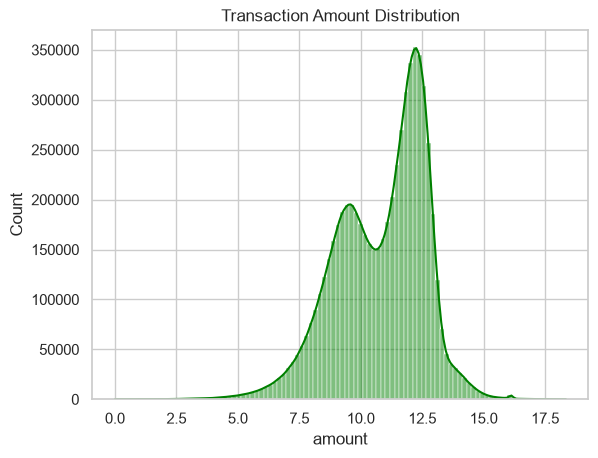

'This showed histogram for logarithmic value of "amount" of transaction'

In [43]:
sns.histplot(np.log1p(df["amount"]), bins=100, kde= True, color="green")
plt.title("Transaction Amount Distribution")
plt.show()

'''This showed histogram for logarithmic value of "amount" of transaction'''

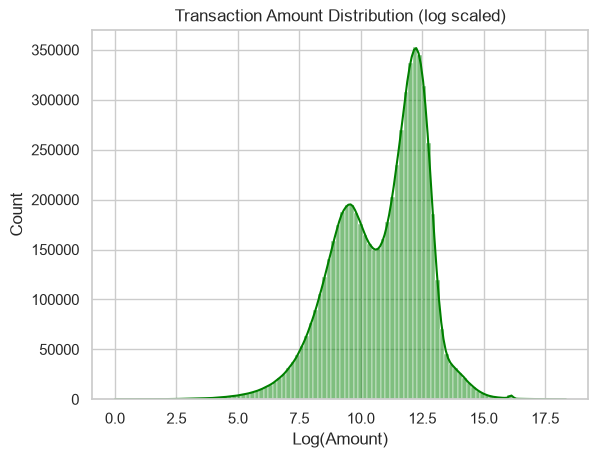

'This showed histogram for logarithmic value of "amount" of transaction'

In [44]:
sns.histplot(np.log1p(df["amount"]), bins=100, kde= True, color="green")
plt.title("Transaction Amount Distribution (log scaled)")
plt.xlabel("Log(Amount)")
plt.show()

'''This showed histogram for logarithmic value of "amount" of transaction'''

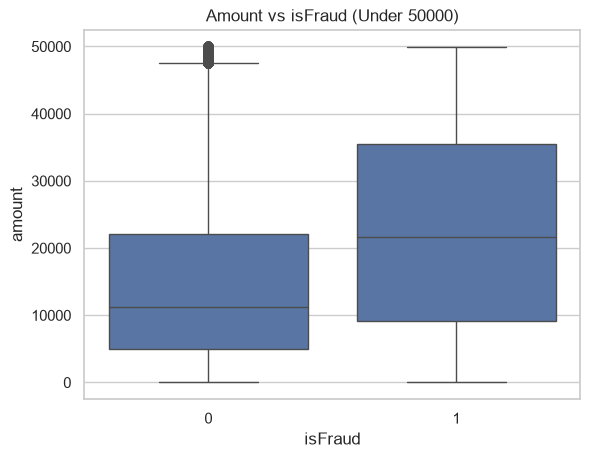

'Forms the candle like graph'

In [45]:
sns.boxplot(data=df[df["amount"]<50000], x= "isFraud", y = "amount")
plt.title("Amount vs isFraud (Under 50000)")
plt.show()

'''Forms the candle like graph'''

In [46]:
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]
(df["balanceDiffOrig"] < 0).sum()
(df["balanceDiffDest"] < 0).sum()
print(df.head(2))

   step     type   amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1  PAYMENT  9839.64  C1231006815       170136.0       160296.36   
1     1  PAYMENT  1864.28  C1666544295        21249.0        19384.72   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  \
0  M1979787155             0.0             0.0        0               0   
1  M2044282225             0.0             0.0        0               0   

   balanceDiffOrig  balanceDiffDest  
0          9839.64              0.0  
1          1864.28              0.0  


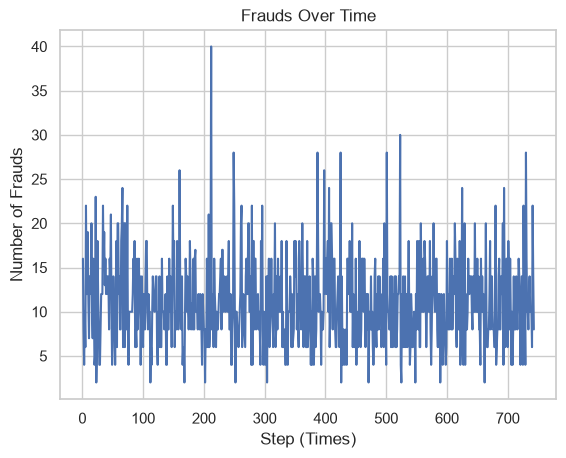

In [47]:
frauds_per_step = df[df["isFraud"]==1]["step"].value_counts().sort_index()
plt.plot(frauds_per_step.index, frauds_per_step.values, label="Frauds per Step")
plt.xlabel("Step (Times)")
plt.ylabel("Number of Frauds")
plt.title("Frauds Over Time")
plt.grid(True)
plt.show()

In [48]:
df.drop(columns="step", inplace=True)
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [49]:
# Now I'll explore consumer level data 
top_senders = df["nameOrig"].value_counts().head(10)
print(top_senders)

nameOrig
C2098525306    3
C400299098     3
C1999539787    3
C1065307291    3
C545315117     3
C1976208114    3
C1784010646    3
C1530544995    3
C1902386530    3
C1677795071    3
Name: count, dtype: int64


In [50]:
top_receivers = df["nameDest"].value_counts().head(10) # sirf top 10 ko lere 
top_receivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [51]:
fraud_users = df[df["isFraud"]==1]["nameOrig"].value_counts().head(10) # top 10 ko lere
fraud_users

nameOrig
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C137533655     1
C1118430673    1
C749981943     1
C1334405552    1
C467632528     1
C1364127192    1
Name: count, dtype: int64

In [52]:
# Correlation matrix visualization
mat = df[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]].corr()
mat

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


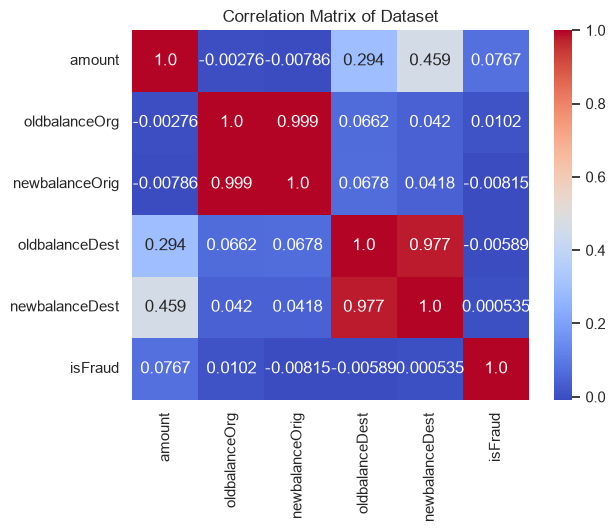

In [53]:
sns.heatmap(mat,annot=True, cmap="coolwarm", fmt="1.3")
plt.title("Correlation Matrix of Dataset")
plt.show()

In [54]:
# Now I am scouting customers who had a bank balance, transfered money and the balance now is 0 
zero_at = df[(df["oldbalanceOrg"])>0 &
             (df["newbalanceOrig"]==0) &
             (df["type"].isin(["TRANSFER", "CASH_OUT"]))]
len(zero_at)

4260171

In [55]:
zero_at.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [56]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import classification_report, confusion_matrix 
from sklearn.pipeline import Pipeline 
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import OneHotEncoder 

In [57]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [58]:
# I'm gonna drop the column names and columns that I'm not gonna use for data modelling atp
df_new = df.drop(["nameOrig", "nameDest", "isFlaggedFraud"], axis = 1)
df_new.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,181.00,0.0
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,181.00,-21182.0
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0


In [59]:
category = ["type"]
topings = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
Y = df_new["isFraud"]
X = df_new.drop("isFraud", axis = 1)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, stratify=Y)

In [ ]:
preprocessor = ColumnTransformer(
    transformers = [("num", StandardScaler(), topings),
                    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), category)],
    remainder = "drop"
)
pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
pipeline.fit(X_train, Y_train)

In [61]:
y_pred = pipeline.predict(X_test)
print(classification_report(Y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1906322
           1       0.02      0.94      0.04      2464

    accuracy                           0.95   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.95      0.97   1908786



In [62]:
confusion_matrix(Y_test,y_pred)

array([[1801537,  104785],
       [    139,    2325]])

In [64]:
pipeline.score(X_test, Y_test)*100

94.50310301940605

In [66]:
import joblib
joblib.dump(pipeline,"fraud_detection.pkl")

# Now this model will be used for checking the fraud 

['fraud_detection.pkl']